<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_25_Category_Selectivity_Via_Cosine_Similarity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from scipy.stats import ttest_ind
import requests

from transformers import AutoModelForCausalLM, AutoTokenizer


# Part_1:Model,Token,hidden_states

## Task_1:
- Import GPT-2-small and its tokenizer. When importing the model,
toggle the optional input argument output_hidden_states to be
True. Switch the model to evaluation mode.
The online code file has a variable words that contains 34 words in
three semantic categories (space, furniture, fruit). Confirm that the
words are each encoded using only one token when they include a
preceding space.

In [2]:
model=AutoModelForCausalLM.from_pretrained('gpt2',output_hidden_states=True)
tokenizer=AutoTokenizer.from_pretrained('gpt2')
model.eval()

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] The following generation flags are not valid and may be ignored: ['output_hidden_states']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [11]:
words = [
    [1, 'galaxy'],
    [1, 'asteroid'],
    [1, 'comet'],
    [1, 'cosmos'],
    [1, 'space'],
    [1, 'sun'],
    [1, 'planet'],
    [1, 'moon'],
    [1, 'star'],
    [1, 'orbit'],
    [2, 'ceiling'],
    [2, 'sofa'],
    [2, 'couch'],
    [2, 'carpet'],
    [2, 'door'],
    [2, 'window'],
    [2, 'lamp'],
    [2, 'chair'],
    [2, 'table'],
    [2, 'rug'],
    [2, 'bed'],
    [2, 'floor'],
    [2, 'wall'],
    [3, 'pear'],
    [3, 'grape'],
    [3, 'banana'],
    [3, 'cherry'],
    [3, 'peach'],
    [3, 'apple'],
    [3, 'seed'],
    [3, 'jelly'],
    [3, 'orange'],
    [3, 'lime'],
    [3, 'fruit'],
]
for w in words:
  t = tokenizer.encode(f' {w[1]}')
  print(f'{w[1]:>10} is token {t}')

    galaxy is token [16161]
  asteroid is token [27460]
     comet is token [31733]
    cosmos is token [39385]
     space is token [2272]
       sun is token [4252]
    planet is token [5440]
      moon is token [8824]
      star is token [3491]
     orbit is token [13066]
   ceiling is token [13387]
      sofa is token [34902]
     couch is token [18507]
    carpet is token [20710]
      door is token [3420]
    window is token [4324]
      lamp is token [20450]
     chair is token [5118]
     table is token [3084]
       rug is token [14477]
       bed is token [3996]
     floor is token [4314]
      wall is token [3355]
      pear is token [25286]
     grape is token [30777]
    banana is token [25996]
    cherry is token [23612]
     peach is token [47565]
     apple is token [17180]
      seed is token [9403]
     jelly is token [27644]
    orange is token [10912]
      lime is token [28738]
     fruit is token [8234]


## Task_2:
- Create a batch of size 34 × 5 tokens, comprising 34 sequences of five
tokens each. Each sequence is the sentence “The next word is X”
where you replace “X” with each of the 34 words.
Push the tokens through the model. Use the code model(batch)
without calling any additional input arguments. Confirm that
the output of that model call still contains a hidden_states vari
able where each element in that variable is a tensor of size 34×5×768.
To confirm that all sequences are identical up to the final to
ken, calculate and plot the variance across sequences for each token,
as in Figure 5.10. The resulting scatter plot of token position (x-axis)
by variance (y-axis) should be all zeros for the first four tokens,
showing that all hidden states are indeed identical.

In [12]:
len(words)

34

In [17]:
# create a batch of tokens
batch = torch.zeros((len(words),5),dtype=torch.long)

for i,w in enumerate(words):
  batch[i,:] = tokenizer.encode(f'The next word is {w[1]}',return_tensors="pt")

# push through the model
with torch.no_grad():
  outs = model(batch)

# check shape of one hidden states (even though they're not toggled on in the above call!)
outs.hidden_states[3].shape


torch.Size([34, 5, 768])

In [23]:
len(outs.hidden_states)

13

In [18]:
outs.logits.shape

torch.Size([34, 5, 50257])

In [16]:
batch

tensor([[  464,  1306,  1573,   318, 16161],
        [  464,  1306,  1573,   318, 27460],
        [  464,  1306,  1573,   318, 31733],
        [  464,  1306,  1573,   318, 39385],
        [  464,  1306,  1573,   318,  2272],
        [  464,  1306,  1573,   318,  4252],
        [  464,  1306,  1573,   318,  5440],
        [  464,  1306,  1573,   318,  8824],
        [  464,  1306,  1573,   318,  3491],
        [  464,  1306,  1573,   318, 13066],
        [  464,  1306,  1573,   318, 13387],
        [  464,  1306,  1573,   318, 34902],
        [  464,  1306,  1573,   318, 18507],
        [  464,  1306,  1573,   318, 20710],
        [  464,  1306,  1573,   318,  3420],
        [  464,  1306,  1573,   318,  4324],
        [  464,  1306,  1573,   318, 20450],
        [  464,  1306,  1573,   318,  5118],
        [  464,  1306,  1573,   318,  3084],
        [  464,  1306,  1573,   318, 14477],
        [  464,  1306,  1573,   318,  3996],
        [  464,  1306,  1573,   318,  4314],
        [ 

In [48]:
outs.hidden_states[3][:,0,:].shape

torch.Size([34, 768])

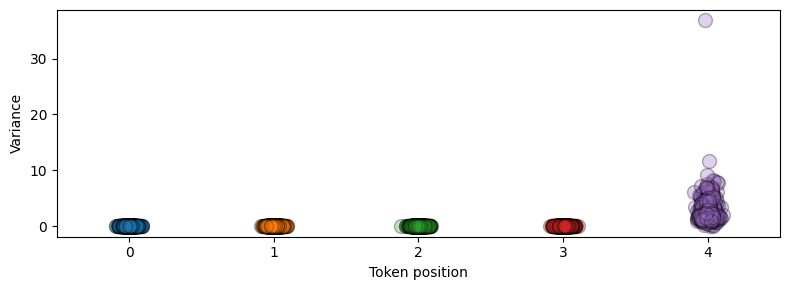

In [50]:
plt.figure(figsize=(8,3))

for i in range(batch.shape[1]):
  hs = outs.hidden_states[3][:,i,:]
  plt.plot(np.random.normal(i,.03,hs.shape[1]),hs.var(dim=0),'o',
           markeredgecolor='k',markersize=10,alpha=.3)

plt.gca().set(xlabel='Token position',ylabel='Variance',
              xticks=range(5),xlim=[-.5,4.5])

plt.tight_layout()
plt.show()

# Part_2:Cosine Similarities in one layer

## Task_1:
- Extract the category labels in the words variable into a NumPy array.
Make sure the array is a 34 × 1 column vector (not a dimensionless
array). Create a “category matrix mask” as the upper-triangle of an
outer product of the labels vector with itself (the outer product is a
linear algebra operation that creates a matrix from a vector as vv⊤).
Visualize that matrix as in Figure 5.11.

(34, 1)


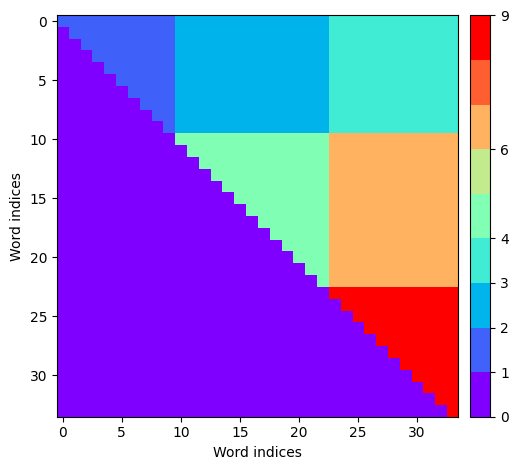

In [63]:
# vector of word categories
labels = np.array([[w[0] for w in words]]).T
print(labels.shape)

# mask for cosine similarity matrix
cat_mask = np.triu( labels @ labels.T)

# create a discrete colormap
N = cat_mask.max()
base = plt.get_cmap('rainbow')
cmapN = base.from_list(None,base(np.linspace(0,1,N)),N)

plt.imshow(cat_mask,cmap=cmapN)
plt.gca().set(xlabel='Word indices',ylabel='Word indices')
plt.colorbar(ticks=np.unique(cat_mask),pad=.02)

plt.tight_layout()
plt.show()

In [55]:
np.triu( labels @ labels.T)

array([[1, 1, 1, ..., 3, 3, 3],
       [0, 1, 1, ..., 3, 3, 3],
       [0, 0, 1, ..., 3, 3, 3],
       ...,
       [0, 0, 0, ..., 9, 9, 9],
       [0, 0, 0, ..., 0, 9, 9],
       [0, 0, 0, ..., 0, 0, 9]], shape=(34, 34))

In [56]:
np.triu( labels @ labels.T,1)

array([[0, 1, 1, ..., 3, 3, 3],
       [0, 0, 1, ..., 3, 3, 3],
       [0, 0, 0, ..., 3, 3, 3],
       ...,
       [0, 0, 0, ..., 0, 9, 9],
       [0, 0, 0, ..., 0, 0, 9],
       [0, 0, 0, ..., 0, 0, 0]], shape=(34, 34))

## Task_2:
- Choose one hidden-state layer (I used layer index 4). Extract
the hidden states for the final token, normalize the vectors, and
calculate the cosine similarity matrix as HH⊤ as you learned in
Chapter 3. Visualize that matrix as in Figure 5.12A and look for
a block-diagonal structure that would indicate differences between
within- vs. across-category similarities.
Extract all the within-category similarities into one vector, and
all the across-category similarities into another vector. Then show
histograms of those two groups as in Figure 5.12B, perform a
two-samples t-test to compare the distributions, and calculate a ∆
term as the difference between the means of the within- (w) and
across-category (a) similarities (∆ = w − a).

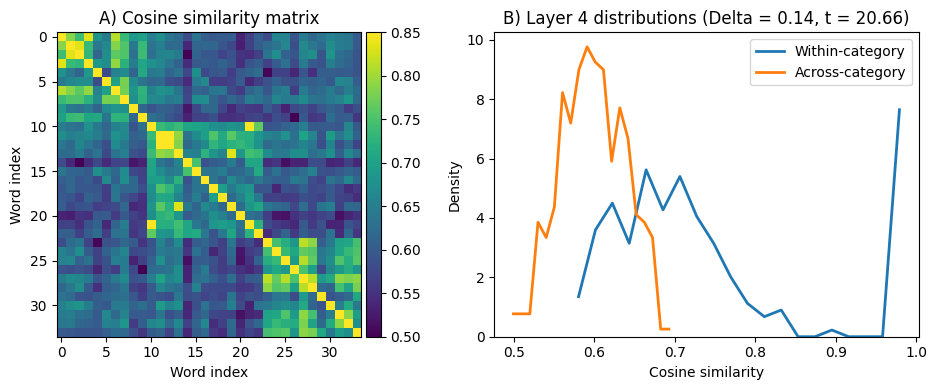

In [75]:
layeri = 4
hs = outs.hidden_states[layeri][:,-1,:]
hs /= torch.linalg.norm(hs,axis=1,keepdims=True)
csMat =  hs@hs.T

# extract the unique values
within = torch.concatenate((csMat[cat_mask==1],csMat[cat_mask==4],csMat[cat_mask==9]))
across = torch.concatenate((csMat[cat_mask==2],csMat[cat_mask==3],csMat[cat_mask==6]))

# t-test
tval = ttest_ind(within,across).statistic

# histograms
yWithin,xWithin = torch.histogram(within,bins=20,density=True)
yAcross,xAcross = torch.histogram(across,bins=20,density=True)

_,axs = plt.subplots(1,2,figsize=(10,4))
h = axs[0].imshow(csMat,vmin=.5,vmax=.85)
plt.colorbar(h,ax=axs[0],pad=.01)
axs[0].set(xlabel='Word index',ylabel='Word index',title='A) Cosine similarity matrix')

axs[1].plot(xWithin[:-1],yWithin,linewidth=2,label='Within-category')
axs[1].plot(xAcross[:-1],yAcross,linewidth=2,label='Across-category')
axs[1].set(ylim=[0,None],xlabel='Cosine similarity',ylabel='Density',
           title=f'B) Layer {layeri} distributions (Delta = {within.mean()-across.mean():.2f}, t = {tval:.2f})')
axs[1].legend()


plt.tight_layout()
plt.show()

# Part 3: Laminar profiles

## Task_1
- In a for-loop over the hidden layers, repeat the analysis you developed
in Part 2, and store the ∆ and t-values for each layer in a NumPy
array. Visualize the results as in Figure 5.13

In [80]:
num_hidden = len(outs.hidden_states)
# names of the layers, for the x-axis tick labels
layer_labels = ['Emb'] + [f'L{i}' for i in range(num_hidden-1)]

In [82]:
num_hidden

13

In [81]:
layer_labels

['Emb',
 'L0',
 'L1',
 'L2',
 'L3',
 'L4',
 'L5',
 'L6',
 'L7',
 'L8',
 'L9',
 'L10',
 'L11']

In [87]:
# initializations
dist_metrics = np.zeros((4,num_hidden))


for layeri in range(num_hidden):

  # cosine similarity matrix
  hs = outs.hidden_states[layeri][:,-1,:].squeeze()
  hs /= np.linalg.norm(hs,axis=1,keepdims=True)
  csMat = hs @hs.T

  # extract the similarity values
  w = torch.concatenate((csMat[cat_mask==1],csMat[cat_mask==4],csMat[cat_mask==9]))
  a = torch.concatenate((csMat[cat_mask==2],csMat[cat_mask==3],csMat[cat_mask==6]))

  # calculate the metrics
  dist_metrics[0,layeri] =w.mean()
  dist_metrics[1,layeri] =a.mean()
  dist_metrics[2,layeri] =w.mean()-a.mean()
  dist_metrics[3,layeri] =ttest_ind(w,a).statistic

/tmp/ipykernel_747/476465112.py:9: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  hs /= np.linalg.norm(hs,axis=1,keepdims=True)


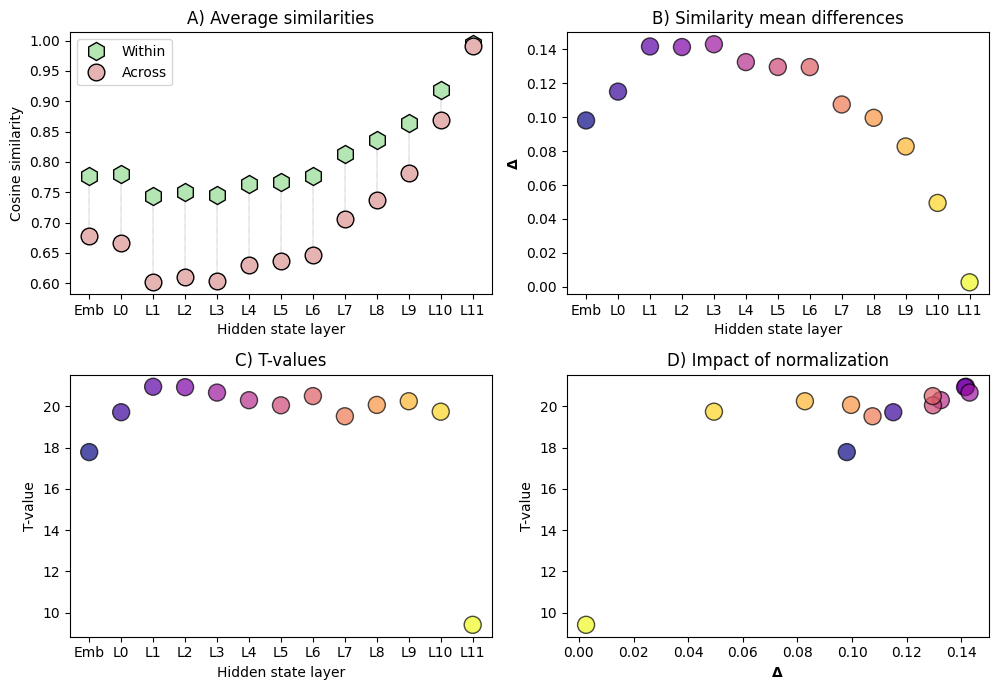

In [90]:
# show the results
_,axs = plt.subplots(2,2,figsize=(10,7))
axs[0,0].plot(dist_metrics[0,:],'kh',markerfacecolor=[.7,.9,.7],markersize=13,label='Within')
axs[0,0].plot(dist_metrics[1,:],'ko',markerfacecolor=[.9,.7,.7],markersize=12,label='Across')

# thin connecting lines representing \Delta
for i in range(1,num_hidden): # plot 0 separately for the legend
  axs[0,0].plot([i,i],dist_metrics[:2,i],'k:',linewidth=.3,zorder=-10)
axs[0,0].plot([0,0],dist_metrics[:2,0],'k:',linewidth=.3,zorder=-10,label='')

axs[0,0].legend()
axs[0,0].set(xlabel='Hidden state layer',xticks=range(len(layer_labels)),xticklabels=layer_labels,
           ylabel='Cosine similarity',title='A) Average similarities')


axs[0,1].scatter(range(num_hidden),dist_metrics[2,:],s=150,edgecolor='k',
            c=plt.cm.plasma(np.linspace(0,1,num_hidden)),alpha=.7)
axs[0,1].set(xlabel='Hidden state layer',xticks=range(len(layer_labels)),xticklabels=layer_labels,
           ylabel='$\\bf\\Delta$',title='B) Similarity mean differences')

axs[1,0].scatter(range(num_hidden),dist_metrics[3,:],s=150,edgecolor='k',
            c=plt.cm.plasma(np.linspace(0,1,num_hidden)),alpha=.7)
axs[1,0].set(xlabel='Hidden state layer',xticks=range(len(layer_labels)),xticklabels=layer_labels,
           ylabel='T-value',title='C) T-values')

axs[1,1].scatter(dist_metrics[2,:],dist_metrics[3,:],s=150,edgecolor='k',
            c=plt.cm.plasma(np.linspace(0,1,num_hidden)),alpha=.7)
axs[1,1].set(xlabel='$\\bf\\Delta$',ylabel='T-value',title='D) Impact of normalization')


plt.tight_layout()
plt.show()


## Task_2:
- For each text sequence in the batch, find the maximum output logit
of the final token, build a text sequence from the input tokens plus
the max-logit token as the newly generated token, and print the texts

In [91]:
for seqi in range(len(words)):

  # find max token
  maxtok = torch.argmax(outs.logits[seqi,-1,:],dim=-1)

  # build and print the sentence
  sentence = f'{tokenizer.decode(batch[seqi])}{tokenizer.decode(maxtok)}'
  print(sentence)


The next word is galaxy.
The next word is asteroid.
The next word is comet.
The next word is cosmos.
The next word is space.
The next word is sun.
The next word is planet.
The next word is moon.
The next word is star.
The next word is orbit.
The next word is ceiling.
The next word is sofa.
The next word is couch.
The next word is carpet.
The next word is door.
The next word is window.
The next word is lampoon
The next word is chair.
The next word is tableau
The next word is rug.
The next word is bedtime
The next word is floor.
The next word is wall.
The next word is pearls
The next word is grapefruit
The next word is banana.
The next word is cherry.
The next word is peach.
The next word is apple.
The next word is seed.
The next word is jelly.
The next word is orange.
The next word is lime.
The next word is fruit.


# Part 4: Same words, different contexts

## Task_1:
- Import and tokenize the text of The Great Gatsby. Find all instances
of the tokens “ years”, “ garage”, and “ lawn” (note the leading
spaces). Confirm that those are single-token words that appear 35,
24, and 27 times in the text. Create an 86×2 NumPy array contain
ing the indices of the target words in the full book token sequence,
and an integer label (“1” for years, “2” for garage, and “3” for lawn).
Create a batch of tokens that is 86 × 51, corresponding to 86
sequences, each comprising one of the three target tokens and their
50 preceding tokens. You can print out some of the token sequences
to confirm that they have the same final words but different contexts.

In [92]:
# GreatGatsby
url = 'https://www.gutenberg.org/cache/epub/64317/pg64317.txt'
text = requests.get(url).text
tokens = np.array( tokenizer.encode(text) )
print(f'There are {len(tokens):,} tokens, {len(set(tokens))} of which are unique.')

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (89263 > 1024). Running this sequence through the model will result in indexing errors


There are 89,263 tokens, 8151 of which are unique.


In [96]:

targets = [' years',' garage', ' lawn']

for i,w in enumerate(targets):

  # this token index
  t = tokenizer.encode(w)

  # find all the matches
  matches = np.where(tokens==t)[0]
  labels = np.full(len(matches),i+1)
  together = np.vstack((matches,labels)).T

  # stitch together
  if i==0:
    target_idxs = together
  else:
    target_idxs = np.vstack((target_idxs,together))

  # print count and confirm single-token words
  print(f'{w:>10} is token {t} and appears {sum(target_idxs[:,1]==(i+1))} times.')

     years is token [812] and appears 35 times.
    garage is token [15591] and appears 24 times.
      lawn is token [21133] and appears 27 times.


In [102]:
together

array([[ 1825,     3],
       [ 2678,     3],
       [ 2770,     3],
       [ 3226,     3],
       [ 7621,     3],
       [10241,     3],
       [18971,     3],
       [19081,     3],
       [21613,     3],
       [25826,     3],
       [27578,     3],
       [30829,     3],
       [34216,     3],
       [34224,     3],
       [34330,     3],
       [37345,     3],
       [37729,     3],
       [38430,     3],
       [40658,     3],
       [41480,     3],
       [54312,     3],
       [67744,     3],
       [68338,     3],
       [71601,     3],
       [71748,     3],
       [83828,     3],
       [84413,     3]])

In [100]:
contextwin = 50

# create a batch
batch = torch.zeros((target_idxs.shape[0],contextwin+1),dtype=torch.long)


for i in range(target_idxs.shape[0]):
  toks = tokens[target_idxs[i,0]-contextwin:target_idxs[i,0]+1]
  batch[i,:] = torch.tensor(toks)

batch.shape




torch.Size([86, 51])

In [101]:

# show last few tokens in each sentence
for b in batch:
  print(tokenizer.decode(b[-5:]))

 younger and more vulnerable years
 since his New Haven years
’s three years
 aunt about a thousand years
 been after me for years
 that garage for eleven years
 person in his middle years

“Several years
, I am fifty years
 just eighteen, two years
 again for over four years

time in years
 He had waited five years
 a Chicago paper for years
t met for many years

“Five years
 pay
five years
t seen me for years
ook me just three years
 be my best friend years
 Almost
five years
Cody was fifty years
shores for five years
ot out those five years
 had obliterated four years
 autumn night, five years
 and the next thirty years
 about it for ten years
 this fellow for five years
 been neighbours for four years
“Twelve years

After two years
 to see me two years
’m five years
 anyone. For forty years
 this shadow of a garage
 impatiently around the garage
 so remarkable in the garage
 been living over that garage
 straining at the garage
 heard of making a garage
’s a garage
 the windows ove

# Part 5: Within- and across-word similarities in one layer

## Task_1:
- Run a forward pass on the batch of tokens. Confirm that the hidden
states tensor for each layer is size 86 × 51 × 768.
Create a category mask-matrix as you did in Part 2. Then re
produce the cosine similarity matrix and distributions as you did in
Part 2 (using data from layer 4), except here you create three groups:
the within-word similarities, the across-word similarities involving
years, and the across-word similarities for garage and lawn. Show
the results as in Figure 5.14

In [103]:
# forward pass (~25 sec on CPU)
with torch.no_grad():
  outs = model(batch)

outs.hidden_states[3].shape


torch.Size([86, 51, 768])

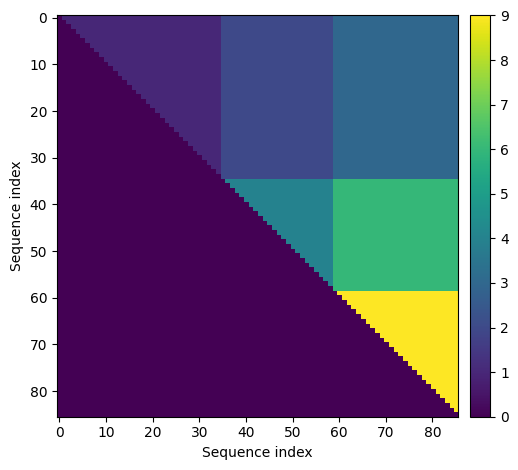

In [104]:
# extract embeddings vectors for final token
activations = outs.hidden_states[3][:,-1,:]

# mask for cosine similarity matrix
cat_mask = np.triu( target_idxs[:,[1]]@target_idxs[:,[1]].T ,1)

plt.imshow(cat_mask)
plt.gca().set(xlabel='Sequence index',ylabel='Sequence index')
plt.colorbar(pad=.02)

plt.tight_layout()
plt.show()


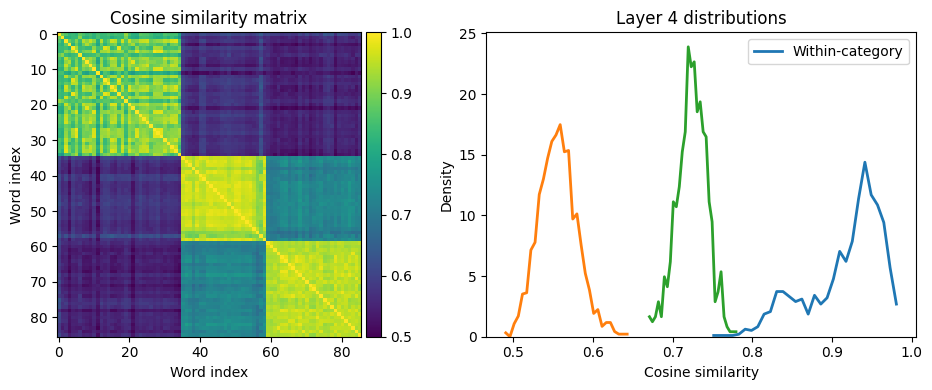

In [105]:
# cosine similarity matrix for one layer
layeri = 4
hs = outs.hidden_states[layeri][:,-1,:]
hs /= torch.linalg.norm(hs,axis=1,keepdims=True)
csMat = hs @ hs.T

# extract the block-wise data
within = torch.concatenate((csMat[cat_mask==1],csMat[cat_mask==4],csMat[cat_mask==9]))
acros1 = torch.concatenate((csMat[cat_mask==2],csMat[cat_mask==3]))
acros2 = csMat[cat_mask==6]

# distributions
yWithin,xWithin = torch.histogram(within,bins=30,density=True)
yAcros1,xAcros1 = torch.histogram(acros1,bins=30,density=True)
yAcros2,xAcros2 = torch.histogram(acros2,bins=30,density=True)


# show the similarity matrix
_,axs = plt.subplots(1,2,figsize=(10,4))
h = axs[0].imshow(csMat,vmin=.5,vmax=1)
plt.colorbar(h,ax=axs[0],pad=.01)
axs[0].set(xlabel='Word index',ylabel='Word index',title='Cosine similarity matrix')

# and the distributions
axs[1].plot(xWithin[:-1],yWithin,linewidth=2,label='Within-category')
axs[1].plot(xAcros1[:-1],yAcros1,linewidth=2,label='')
axs[1].plot(xAcros2[:-1],yAcros2,linewidth=2,label='')
axs[1].set(ylim=[0,None],xlabel='Cosine similarity',ylabel='Density',
           title=f'Layer {layeri} distributions')
axs[1].legend()

plt.tight_layout()
plt.savefig('ch5_proj25_part5b.png')
plt.show()

# Part 6: Laminar profiles of similarity distributions

## Task_1:
- In a for-loop over the hidden layers, repeat the analysis from Part 5,
but use the same bin boundaries of .4 to 1 in 35 steps. The outputs
of torch.histogram with density=True is normalized to bin width,
but you should re-normalize it to probability by multiplying the
density values by dx, which is the width of the bins.
Show the results in three heatmaps, one per category, as in
Figure 5.15

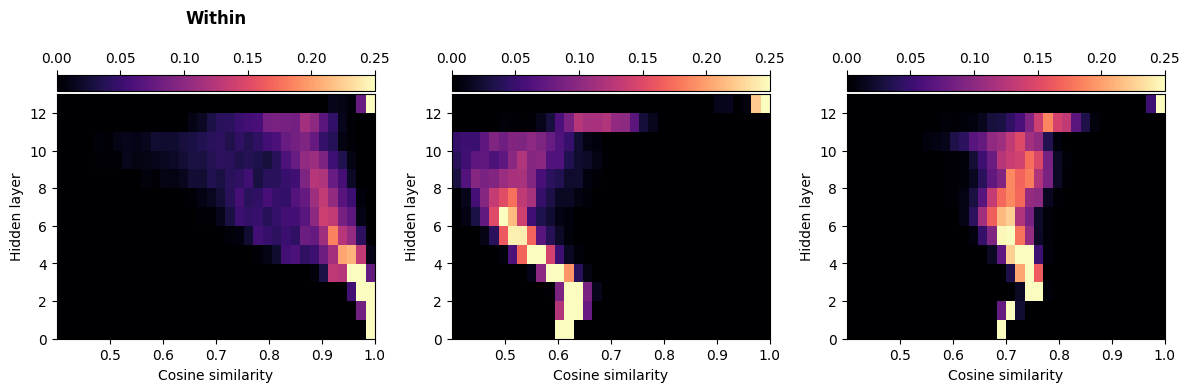

In [106]:
# common histogram bins for all distributions
binedges = torch.linspace(.4,1,35)
dx = binedges[1]-binedges[0]

# initialize: grouping X layer X bin
cs_dists = torch.zeros((3,num_hidden,len(binedges)-1))

# loop over layers
for layeri in range(num_hidden):

  # calculate the similarity matrix
  hs = outs.hidden_states[layeri][:,-1,:]
  hs /= torch.linalg.norm(hs,axis=1,keepdims=True)
  csMat = hs @ hs.T

  # extract the category elements
  within = torch.concatenate((csMat[cat_mask==1],csMat[cat_mask==4],csMat[cat_mask==9]))
  acros1 = torch.concatenate((csMat[cat_mask==2],csMat[cat_mask==3]))
  acros2 = csMat[cat_mask==6]

  # calculate the histograms
  cs_dists[0,layeri,:],_ = torch.histogram(within,bins=binedges,density=True)
  cs_dists[1,layeri,:],_ = torch.histogram(acros1,bins=binedges,density=True)
  cs_dists[2,layeri,:],_ = torch.histogram(acros2,bins=binedges,density=True)


# transform from density to probability/dx
cs_dists *= dx


# the tornado plots :D
_,axs = plt.subplots(1,3,figsize=(12,4))

titles = [ 'Within','','' ]

# generate the plots
for i in range(3):
  h = axs[i].imshow(cs_dists[i,:,:],vmin=0,vmax=.25,aspect='auto',origin='lower',
                extent=[binedges[0],binedges[-1],0,num_hidden],cmap='magma')
  plt.colorbar(h,ax=axs[i],orientation='horizontal',location='top',pad=.01)
  axs[i].set(xlabel='Cosine similarity',ylabel='Hidden layer')
  axs[i].set_title(titles[i]+'\n\n\n',fontweight='bold')

plt.tight_layout()
plt.show()